# Лабораторная работа № 1. Задание 3
## Собственная реализация блокировки чтения-записи

### Алгоритм и реализация (`my_rwlock.c`)

Структура `my_rwlock_t` содержит поля, предложенные в задании:

| Поле | Назначение |
|---|---|
| `mutex` | защищает все остальные поля структуры |
| `read_cond` | условная переменная, на которой ждут читатели |
| `write_cond` | условная переменная, на которой ждут писатели |
| `readers_count` | сколько потоков сейчас читают |
| `wating_readers_count` | сколько читателей ждут на `read_cond` |
| `wating_writers_count` | сколько писателей ждут на `write_cond` |
| `writer_active` | 1, если блокировку держит писатель |

Основные функции:

```c
int my_rwlock_rdlock(my_rwlock_t* lock) {
    pthread_mutex_lock(&lock->mutex);
    ++lock->wating_readers_count;
    while (lock->writer_active)
        pthread_cond_wait(&lock->read_cond, &lock->mutex);
    --lock->wating_readers_count;
    ++lock->readers_count;
    pthread_mutex_unlock(&lock->mutex);
    return 0;
}

int my_rwlock_wrlock(my_rwlock_t* lock) {
    pthread_mutex_lock(&lock->mutex);
    ++lock->wating_writers_count;
    while (lock->writer_active || lock->readers_count > 0)
        pthread_cond_wait(&lock->write_cond, &lock->mutex);
    --lock->wating_writers_count;
    lock->writer_active = 1;
    pthread_mutex_unlock(&lock->mutex);
    return 0;
}

int my_rwlock_unlock(my_rwlock_t* lock) {
    pthread_mutex_lock(&lock->mutex);
    if (lock->readers_count > 0) --lock->readers_count;
    else lock->writer_active = 0;
    if (lock->readers_count == 0) {
        if (lock->wating_writers_count > 0) pthread_cond_signal(&lock->write_cond);
        else if (lock->wating_readers_count > 0) pthread_cond_broadcast(&lock->read_cond);
    }
    pthread_mutex_unlock(&lock->mutex);
    return 0;
}
```

**Пояснения к коду:**

- Все поля читаются и изменяются только под `mutex`. Поэтому проверка условия («есть ли писатель») и изменение счётчиков не могут перемешаться с действиями других потоков.
- Ожидание выполняется в цикле `while (условие) pthread_cond_wait(...)`. `pthread_cond_wait` может проснуться без условия, по этому используем в цикле.
- **Читатель** входит, если нет активного писателя. Число одновременных читателей не ограничено.
- **Писатель** входит, если нет ни активного писателя, ни читателей.
- **`unlock`** определяет, кто его вызвал, по `readers_count`: пока блокировку держит писатель, `readers_count == 0`, а пока держат читатели, `writer_active == 0`. Когда блокировка полностью освободилась (`readers_count == 0`), будится один ожидающий писатель (`pthread_cond_signal`), а если писателей нет, то все ожидающие читатели (`pthread_cond_broadcast`). Если никто не ждёт, условные переменные не затрагиваются.
- **Политика.** Новые читатели не пропускают вперёд ожидающих писателей, как и в glibc по умолчанию (`PTHREAD_RWLOCK_PREFER_READER_NP`). Поэтому при непрерывном потоке читателей писатель может ждать долго. При освобождении блокировки приоритет отдаётся ожидающему писателю.
- `my_rwlock_init` / `my_rwlock_destroy` обнуляют счётчики, инициализируют и уничтожают мьютекс и условные переменные.


На работе я занимался прифетчером, и в процессе работы над кодом лабы у меня возникла идея протестировать, какой прирост производительности даст выравнивание структуры по границе кэш-строки. Я подготовил оптимизированную версию структуры с таким выравниванием, чтобы при инвалидации одной кэш-строки не инвалидировались соседние кэш-строки, в которых лежат поля структуры, не менявшиеся и потенциально использующиеся параллельно другими ядрами.
**Вариант с выравниванием (флаг `-DMY_RWLOCK_ALIGNED`).** На x86-64 `pthread_mutex_t` занимает 40 байт, `pthread_cond_t` — 48 байт. В исходном порядке полей (`sizeof = 152`) мьютекс лежит по смещению 0, а счётчики — по смещению 136, то есть в другой 64-байтной кэш-строке, и каждая операция изменяет две строки. В выровненном варианте мьютекс и четыре счётчика (40 + 16 = 56 байт) помещены в одну кэш-строку, условные переменные (они нужны только при ожидании) — в следующую, а вся структура выровнена по 64 байта (`__attribute__((aligned(64)))`), чтобы не делить кэш-строки с соседними переменными:

```c
typedef struct {
    pthread_mutex_t mutex;                                   /* одна строка: 56 байт */
    int readers_count;
    int wating_readers_count;
    int wating_writers_count;
    int writer_active;
    pthread_cond_t read_cond __attribute__((aligned(64)));   /* следующая строка */
    pthread_cond_t write_cond;
} __attribute__((aligned(64))) my_rwlock_t;
```

**Подключение к тесту.** В `pth_ll_rwl.c` вызовы `pthread_rwlock_*` заменены макросами `rwlock_init`, `rwlock_rdlock`, `rwlock_wrlock`, `rwlock_unlock`, `rwlock_destroy`. При компиляции с `-DMY_RWLOCK` они раскрываются в `my_rwlock_*`, без флага — в `pthread_rwlock_*`. Код списка и потоков не менялся, поэтому обе реализации сравниваются на одной и той же программе.

**Проверка корректности:**

- 30 запусков по 16 потоков (100 ключей, 20 000 операций, 50 % поиска, 25 % вставок, 25 % удалений) для сборок с `-O2`, `-O0` и с выравниванием: все запуски завершились, суммарное число выполненных операций совпадает с заданным.
- Сборка с ThreadSanitizer (`-fsanitize=thread`, 8 потоков, 100 000 операций): предупреждений о гонках данных нет.

### Аппаратная платформа и методика измерений

| Параметр | Значение |
|---|---|
| Процессор | AMD Ryzen 7 4800H |
| Архитектура | x86_64 (Zen 2) |
| Ядра / логические процессоры | 8 / 16 |
| Кэш | L1d 32 КиБ и L2 512 КиБ на ядро |
| Среда выполнения | Ubuntu 24.04, WSL2; Linux 6.6.87.2-microsoft-standard-WSL2 |
| Компилятор | GCC 13.3.0, флаги `-O2 -pthread` |
| Библиотека | glibc 2.39 |

Сравнивались три сборки одной программы `pth_ll_rwl`:

| Сборка | Флаги | Реализация rwlock |
|---|---|---|
| glibc | — | `pthread_rwlock_t` |
| my_rwlock | `-DMY_RWLOCK` | `my_rwlock_t`, исходный порядок полей |
| my_rwlock + выравнивание | `-DMY_RWLOCK -DMY_RWLOCK_ALIGNED` | `my_rwlock_t`, мьютекс и счётчики в одной кэш-строке |

Использовались три набора входных данных:

| Тест | Ключей в начальном списке | Всего операций | Поиск / вставка / удаление | Что проверяет |
|---|---:|---:|---|---|
| READ | 1000 | 1 000 000 | 99,9 / 0,05 / 0,05 % | почти только чтение, список средней длины |
| LOCK | 10 | 2 000 000 | 99,9 / 0,05 / 0,05 % | почти только чтение, короткий список: время уходит в основном на блокировку |
| MIXED | 1000 | 100 000 | 80 / 10 / 10 % | заметная доля записей |

Число потоков: 1, 2, 4, 8, 16.


**Дополнительные измерения** (нужны, чтобы объяснить разницу во времени):

- *число засыпаний потоков* (добровольных переключений контекста) и *процессорное время в ядре* — утилитой GNU time (`/usr/bin/time`, поля `%w` и `%S`);
- *число атомарных инструкций* — счётчиками процессора `ls_locks.*` через `perf stat`;
- *число заполнений строк кэша L1D из L3 или из кэша другого ядра* — счётчиком `ls_refills_from_sys.ls_mabresp_lcl_cache`. Он показывает, как часто данные, изменённые другим ядром, приходится забирать заново.

Счётчики `perf` снимались **отдельными запусками**: под `perf` число засыпаний заметно меняется (для my_rwlock в тесте LOCK на 16 потоках ~115 тыс. вместо ~175 тыс.). Для дополнительных величин приводится медиана по 5 запускам.

Команды (на примере теста LOCK, 16 потоков):

```sh
gcc -O2 -I. pth_ll_rwl/pth_ll_rwl.c pth_ll_rwl/my_rand.c -o build/glibc -pthread
gcc -O2 -I. -DMY_RWLOCK pth_ll_rwl/pth_ll_rwl.c pth_ll_rwl/my_rand.c -o build/my -pthread
gcc -O2 -I. -DMY_RWLOCK -DMY_RWLOCK_ALIGNED pth_ll_rwl/pth_ll_rwl.c pth_ll_rwl/my_rand.c -o build/my_al -pthread

printf '10\n2000000\n0.999\n0.0005\n' > build/in_LOCK.txt

/usr/bin/time -f 'sleeps=%w user=%U sys=%S' build/my 16 < build/in_LOCK.txt

perf stat -e ls_locks.non_spec_lock,ls_locks.spec_lock_lo_spec,ls_locks.spec_lock_hi_spec,ls_refills_from_sys.ls_mabresp_lcl_cache \
    build/my 16 < build/in_LOCK.txt
```

Сумма трёх счётчиков `ls_locks.*` равна числу выполненных атомарных инструкций. 

### Результаты производительности

Время в секундах, в каждой ячейке «среднее / минимальное» по 5 запускам.

**Тест READ** (1000 ключей, 99,9 % поиска, 10⁶ операций):

| Потоков | glibc | my_rwlock | my_rwlock + выравнивание |
|---:|---:|---:|---:|
| 1 | 0,8759 / 0,8686 | 0,8908 / 0,8864 | 0,8953 / 0,8939 |
| 2 | 0,5057 / 0,4931 | 0,5317 / 0,5213 | 0,5313 / 0,5232 |
| 4 | 0,4159 / 0,3999 | 0,4343 / 0,4298 | 0,4180 / 0,4032 |
| 8 | 0,4678 / 0,4576 | 0,4505 / 0,4378 | **0,3962 / 0,3859** |
| 16 | 0,4469 / 0,4415 | 0,4971 / 0,4857 | **0,4003 / 0,3915** |

**Тест LOCK** (10 ключей, 99,9 % поиска, 2·10⁶ операций):

| Потоков | glibc | my_rwlock | my_rwlock + выравнивание |
|---:|---:|---:|---:|
| 1 | 0,5099 / 0,5014 | 0,5158 / 0,5076 | 0,5146 / 0,5116 |
| 2 | **0,4857 / 0,4640** | 0,5625 / 0,5588 | 0,5402 / 0,5326 |
| 4 | **0,4964 / 0,4907** | 0,6873 / 0,6794 | 0,6046 / 0,5926 |
| 8 | **0,5847 / 0,5760** | 0,8823 / 0,8665 | 0,7408 / 0,7059 |
| 16 | **0,6663 / 0,6442** | 1,0896 / 1,0529 | 0,8838 / 0,8755 |

**Тест MIXED** (1000 ключей, 80 / 10 / 10 %, 10⁵ операций):

| Потоков | glibc | my_rwlock | my_rwlock + выравнивание |
|---:|---:|---:|---:|
| 1 | 0,8812 / 0,8692 | 0,9078 / 0,8760 | 0,9012 / 0,8834 |
| 2 | 2,0018 / 1,9731 | **1,7783 / 1,7078** | 1,7890 / 1,7443 |
| 4 | **2,1513 / 2,1163** | 2,2673 / 2,1597 | 2,2852 / 2,2084 |
| 8 | **2,4603 / 2,4376** | 2,8853 / 2,8190 | 2,8604 / 2,8141 |
| 16 | **3,1182 / 3,0731** | 3,6520 / 3,6169 | 3,6701 / 3,6035 |

**Среднее время выполнения в зависимости от количества потоков:**

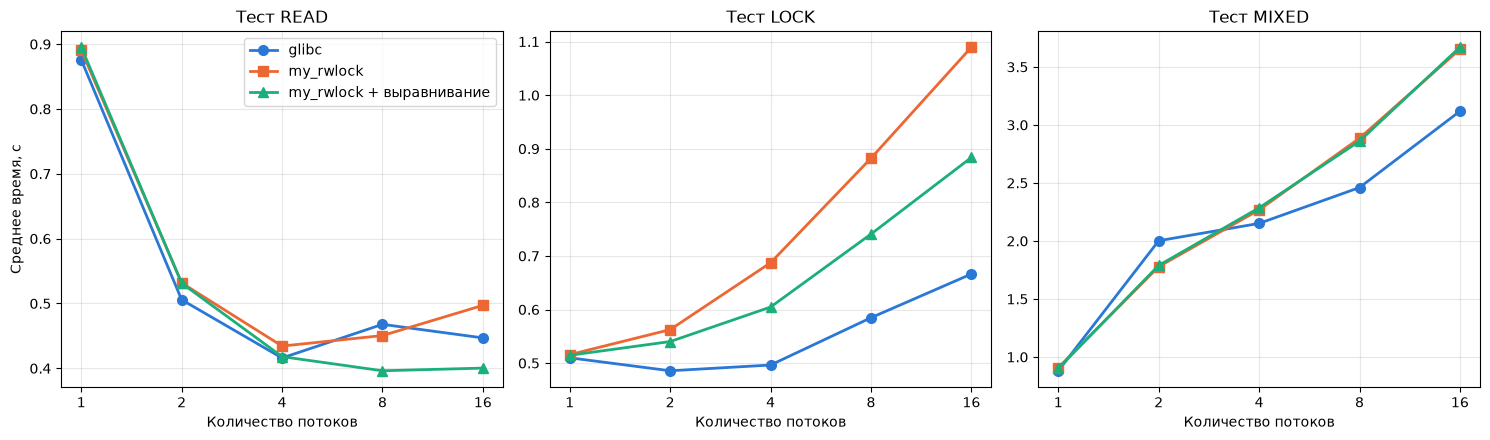

In [4]:
import matplotlib.pyplot as plt

threads = [1, 2, 4, 8, 16]
mean_time = {
    "READ": {
        "glibc": [0.8759, 0.5057, 0.4159, 0.4678, 0.4469],
        "my_rwlock": [0.8908, 0.5317, 0.4343, 0.4505, 0.4971],
        "my_rwlock + выравнивание": [0.8953, 0.5313, 0.4180, 0.3962, 0.4003],
    },
    "LOCK": {
        "glibc": [0.5099, 0.4857, 0.4964, 0.5847, 0.6663],
        "my_rwlock": [0.5158, 0.5625, 0.6873, 0.8823, 1.0896],
        "my_rwlock + выравнивание": [0.5146, 0.5402, 0.6046, 0.7408, 0.8838],
    },
    "MIXED": {
        "glibc": [0.8812, 2.0018, 2.1513, 2.4603, 3.1182],
        "my_rwlock": [0.9078, 1.7783, 2.2673, 2.8853, 3.6520],
        "my_rwlock + выравнивание": [0.9012, 1.7890, 2.2852, 2.8604, 3.6701],
    },
}
colors = {"glibc": "#2a78d6", "my_rwlock": "#eb6834", "my_rwlock + выравнивание": "#1baf7a"}
markers = {"glibc": "o", "my_rwlock": "s", "my_rwlock + выравнивание": "^"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (test, series) in zip(axes, mean_time.items()):
    for name, values in series.items():
        ax.plot(threads, values, marker=markers[name], markersize=7, linewidth=2,
                color=colors[name], label=name)
    ax.set_xscale("log", base=2)
    ax.set_xticks(threads)
    ax.set_xticklabels(threads)
    ax.set_xlabel("Количество потоков")
    ax.set_title(f"Тест {test}")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Среднее время, с")
axes[0].legend()
plt.tight_layout()
plt.show()

### Почему реализации различаются

Чтобы объяснить разницу во времени, для теста LOCK (где время уходит в основном на блокировку) сняты дополнительные величины, медианы по 5 запускам:

| Потоков | Реализация | Засыпаний потоков | Время в ядре, с | Атомарных инструкций на операцию | Заполнений из чужого кэша на операцию |
|---:|---|---:|---:|---:|---:|
| 1 | glibc | 2 | 0,00 | 2,01 | 0,02 |
| 1 | my_rwlock | 2 | 0,00 | 4,00 | 0,01 |
| 1 | my_rwlock + выравн. | 1 | 0,00 | 4,00 | 0,01 |
| 4 | glibc | 7 059 | 0,17 | 2,04 | 1,44 |
| 4 | my_rwlock | 34 982 | 0,64 | 4,45 | 2,26 |
| 4 | my_rwlock + выравн. | 15 214 | 0,45 | 4,46 | 1,63 |
| 8 | glibc | 8 449 | 0,22 | 2,04 | 1,46 |
| 8 | my_rwlock | 107 130 | 2,18 | 4,44 | 3,47 |
| 8 | my_rwlock + выравн. | 47 408 | 1,43 | 4,47 | 2,51 |
| 16 | glibc | 8 756 | 0,23 | 2,04 | 1,51 |
| 16 | my_rwlock | 167 975 | 4,70 | 4,49 | 4,64 |
| 16 | my_rwlock + выравн. | 83 199 | 3,29 | 4,50 | 3,34 |

«Время в ядре» — процессорное время, суммированное по всем потокам, поэтому оно может превышать время выполнения программы.

**Число засыпаний потоков в тесте LOCK:**

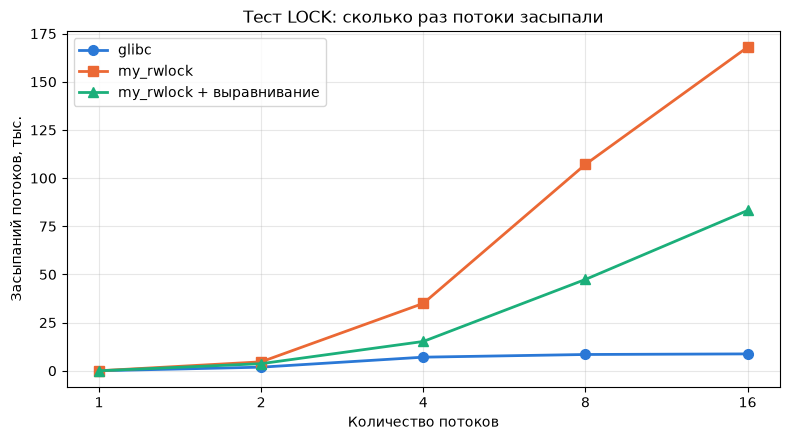

In [5]:
import matplotlib.pyplot as plt

threads = [1, 2, 4, 8, 16]
sleeps = {
    "glibc": [2, 1871, 7059, 8449, 8756],
    "my_rwlock": [2, 4637, 34982, 107130, 167975],
    "my_rwlock + выравнивание": [1, 3681, 15214, 47408, 83199],
}
colors = {"glibc": "#2a78d6", "my_rwlock": "#eb6834", "my_rwlock + выравнивание": "#1baf7a"}
markers = {"glibc": "o", "my_rwlock": "s", "my_rwlock + выравнивание": "^"}

plt.figure(figsize=(8, 4.5))
for name, values in sleeps.items():
    plt.plot(threads, [v / 1000 for v in values], marker=markers[name], markersize=7,
             linewidth=2, color=colors[name], label=name)
plt.xscale("log", base=2)
plt.xticks(threads, threads)
plt.xlabel("Количество потоков")
plt.ylabel("Засыпаний потоков, тыс.")
plt.title("Тест LOCK: сколько раз потоки засыпали")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**1. Один поток — реализации равны.** Без конкуренции(один поток) время одинаково (например LOCK: 0,51 с у всех трёх). glibc выполняет 2 атомарные инструкции на операцию, my_rwlock — 4, но без конкуренции это почти ничего не стоит.

**2. Откуда 2 и 4 атомарные инструкции.** 
В glibc вокруг счётчика читателей нет мьютекса. glibc упаковывает информацию необхадимую для читателя в одно 32-битное число `__readers`: в нём хранится и число читателей, и флаг "сейчас пишет писатель". И с помощью атомарной операции выполняет инкремент над нужным полем, функция для этого - `__atomic_compare_exchange_n(&state, &s, s + 1, ...)`. Засыпает читатель в glibc только когда работает писатель и читать действительно нельзя. Поэтому у glibc 8.8 тыс. засыпаний против наших 168 тыс (на 16 потоках). То есть к изменению значения переменной как в glibc мы так же добавили блок/разблок мьютекса, что дало 2 атомарные инструкции на операцию.

**3. Главная причина отставания — засыпания на внутреннем мьютексе.** Из текста выше следует и отставание по времени: на 16 потоках glibc — 0,67 с, my_rwlock — 1,09 с. Время в ядре у glibc — 0,23 с, у my_rwlock — 4,70 с или 3,29 для выравненной версии. То есть у нас потоки чаще засыпают и дольше спят. Число засыпаний растёт с числом потоков, потому что конкуренция за мьютекс растёт, в то время как в glibc операции чтения не дерутся за мьютексы, если писатель не пишет. 

**4. Влияние выравнивания.** Пока поток держит мьютекс, все остальные ждут, и чем дольше он его держит, тем чаще другие засыпают. В исходной структуре мьютекс и readers_count лежат далеко друг от друга, в разных кусках памяти по 64 байта. Захватив мьютекс, поток ещё ждёт, пока подгрузится второй кусок со счётчиком, и всё это время держит мьютекс. После перестановки они лежат в одном куске и подгружаются разом. Мьютекс держится меньше, засыпаний вдвое меньше, время на 24% ниже (24% для READ 16, 23% для LOCK 16, +-0% для MIXED).

**5. Тест READ.** Список длиннее, и доля времени на блокировку меньше, поэтому разница небольшая. На 8–16 потоках выровненный вариант оказался быстрее glibc (0,40 против 0,45 с на 16 потоках). Причина этого не удалось установить.

**6. Тест MIXED.** На 2 потоках my_rwlock быстрее glibc (1,78 против 2,00 с), на 8–16 потоках glibc быстрее примерно на 15 %. Выравнивание в этом тесте на время не влияет.

**Ограничения измерений.** Замеры выполнены в WSL2, где на результаты влияют другие процессы и планировщик хост-системы.

### Вывод

Реализованная блокировка чтения-записи на основе мьютекса и двух условных переменных работает корректно (стресс-тесты и ThreadSanitizer). На одном потоке она не уступает библиотечной. С ростом числа потоков glibc выигрывает: в тесте LOCK на 16 потоках — 0,67 с против 1,09 с. Причина в том, что в my_rwlock читатели конкурируют за внутренний мьютекс и при столкновении засыпают, тогда как в glibc читатель входит одной атомарной инструкцией без мьютекса. Перестановка полей так, чтобы мьютекс и счётчики находились в одной кэш-строке, сократила время в этом тесте на ~23 % (до 0,88 с) и вдвое уменьшила число засыпаний, но разрыв с glibc не устранила. Для этого нужен быстрый путь на атомарных операциях без мьютекса, как в glibc.